In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


In [2]:
CELLTYPE_BASE = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "preprocessing/pkl_files_filtered_with_celltype"
)

# Change this only if the saved NN .pth files are in another directory.
NN_OUTPUT_DIR = Path(".")

OUT_DIR = Path("./cramers_v_lineage_celltype_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "treutlein": {
        "label": "HBO1",
        "prefix": "treutlein_all_genes",
        "annotated_pkl": CELLTYPE_BASE / "treutlein_all_genes.pkl",
        "expected_total_nn_cells": 5259,
        "expected_lineages": 23,
    },
    "weinreb": {
        "label": "MHSPC",
        "prefix": "weinreb_all_genes",
        "annotated_pkl": CELLTYPE_BASE / "weinreb_all_genes.pkl",
        "expected_total_nn_cells": 1807,
        "expected_lineages": 15,
    },
}

DATASETS


{'treutlein': {'label': 'HBO1',
  'prefix': 'treutlein_all_genes',
  'annotated_pkl': PosixPath('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/treutlein_all_genes.pkl'),
  'expected_total_nn_cells': 5259,
  'expected_lineages': 23},
 'weinreb': {'label': 'MHSPC',
  'prefix': 'weinreb_all_genes',
  'annotated_pkl': PosixPath('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/weinreb_all_genes.pkl'),
  'expected_total_nn_cells': 1807,
  'expected_lineages': 15}}

## Define the original `CustomDataset` class

PyTorch needs the class name to exist when unpickling the saved dataset objects.


In [3]:
class CustomDataset(Dataset):
    def __init__(self, dataframe, indices=None):
        if indices is not None:
            self.dataframe = dataframe.iloc[indices].reset_index(drop=True)
        else:
            self.dataframe = dataframe.copy()

        self.labels = self.dataframe["barcode_NN"].values
        self.features = self.dataframe.drop(
            ["barcode_cont", "barcode_NN"], axis=1
        ).values

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.features[idx], dtype=torch.float),
            torch.tensor(self.labels[idx], dtype=torch.long),
        )


In [7]:
def load_saved_split(prefix, split):
    path = NN_OUTPUT_DIR / f"{prefix}_{split}_dataset.pth"

    if not path.exists():
        raise FileNotFoundError(
            f"Could not find: {path}\n"
            "Set NN_OUTPUT_DIR to the folder containing the saved NN .pth files."
        )

    obj = torch.load(path, map_location="cpu")

    if hasattr(obj, "dataframe"):
        df = obj.dataframe.copy()
    elif isinstance(obj, pd.DataFrame):
        df = obj.copy()
    else:
        raise TypeError(
            f"Unexpected object in {path}: {type(obj)}. "
            "Expected a CustomDataset with a .dataframe attribute."
        )

    df["__split__"] = split
    df["__split_row__"] = np.arange(len(df))

    return df


def load_all_saved_splits(prefix):
    split_dfs = {
        split: load_saved_split(prefix, split)
        for split in ["training", "validation", "test"]
    }

    all_df = pd.concat(
        split_dfs.values(),
        axis=0,
        ignore_index=True,
    )

    return split_dfs, all_df


def make_fingerprint(df, genes, barcode_col):
    # Cast expression to one common dtype in both source files so hashing
    # does not depend on pandas dtype differences.
    x = df.loc[:, genes].astype(np.float32).copy()
    x["__barcode__"] = df[barcode_col].astype(str).to_numpy()

    return pd.util.hash_pandas_object(
        x,
        index=False,
    ).astype("uint64")


def choose_signature_genes(saved_all, common_genes, n_genes):
    # Avoid calculating variance over every gene at once.
    # First take up to 2,500 genes spread across the complete gene list,
    # then retain the most variable genes among those candidates.
    n_candidates = min(2500, len(common_genes))

    candidate_positions = np.linspace(
        0,
        len(common_genes) - 1,
        n_candidates,
        dtype=int,
    )

    candidate_genes = [common_genes[i] for i in candidate_positions]

    variances = (
        saved_all[candidate_genes]
        .astype(np.float32)
        .var(axis=0)
        .sort_values(ascending=False)
    )

    return variances.index[: min(n_genes, len(variances))].tolist()


def match_nn_cells_to_annotations(dataset_key):
    cfg = DATASETS[dataset_key]

    print("=" * 80)
    print(cfg["label"], f"({dataset_key})")
    print("=" * 80)

    # ------------------------------------------------------------
    # Load exact saved NN splits
    # ------------------------------------------------------------
    split_dfs, saved_all = load_all_saved_splits(cfg["prefix"])

    print("\nSaved NN split sizes:")
    for split, df in split_dfs.items():
        print(f"  {split:10s}: {len(df):,}")
    print(f"  {'total':10s}: {len(saved_all):,}")

    if len(saved_all) != cfg["expected_total_nn_cells"]:
        raise ValueError(
            f"Expected {cfg['expected_total_nn_cells']:,} total NN cells for "
            f"{cfg['label']}, but loaded {len(saved_all):,}."
        )

    # ------------------------------------------------------------
    # Load annotated expression + cell-type PKL
    # Column structure used in the cell-type analysis:
    # [... genes ... | cell type | barcode]
    # ------------------------------------------------------------
    annotated = pd.read_pickle(cfg["annotated_pkl"])

    celltype_col = annotated.columns[-2]
    annotated_barcode_col = annotated.columns[-1]

    print("\nAnnotated PKL:")
    print(f"  shape:        {annotated.shape}")
    print(f"  cell type:    {celltype_col}")
    print(f"  barcode:      {annotated_barcode_col}")

    # Saved NN data use barcode_cont explicitly.
    saved_barcode_col = "barcode_cont"

    if saved_barcode_col not in saved_all.columns:
        raise KeyError(
            f"{saved_barcode_col!r} not found in saved NN dataset."
        )

    # ------------------------------------------------------------
    # Restrict annotation file to the lineage classes used by the NN.
    # The NN was trained only on lineages with >=95 cells.
    # ------------------------------------------------------------
    nn_lineages = set(saved_all[saved_barcode_col].astype(str))

    annotated_nn = annotated.loc[
        annotated[annotated_barcode_col].astype(str).isin(nn_lineages)
    ].copy()

    n_lineages = saved_all[saved_barcode_col].astype(str).nunique()

    print(f"\nNN lineage classes: {n_lineages}")
    print(f"Annotated cells in those lineages: {len(annotated_nn):,}")

    if n_lineages != cfg["expected_lineages"]:
        raise ValueError(
            f"Expected {cfg['expected_lineages']} lineage classes for "
            f"{cfg['label']}, found {n_lineages}."
        )

    if len(annotated_nn) != len(saved_all):
        raise ValueError(
            "After restricting the annotated PKL to the NN lineages, the "
            "number of cells does not equal the saved NN cohort.\n"
            f"Saved NN cohort: {len(saved_all):,}\n"
            f"Annotated cohort: {len(annotated_nn):,}\n"
            "Stop here and inspect preprocessing before matching."
        )

    # ------------------------------------------------------------
    # Find expression columns shared by saved NN and annotated PKLs.
    # ------------------------------------------------------------
    saved_metadata = {
        "barcode_cont",
        "barcode_NN",
        "__split__",
        "__split_row__",
    }
    annotated_metadata = {
        celltype_col,
        annotated_barcode_col,
    }

    common_genes = [
        c for c in saved_all.columns
        if c not in saved_metadata
        and c in annotated_nn.columns
        and c not in annotated_metadata
    ]

    print(f"Common expression genes: {len(common_genes):,}")

    if len(common_genes) < 20:
        raise ValueError(
            "Too few common expression columns to identify cells reliably."
        )

    # ------------------------------------------------------------
    # Try increasingly detailed fingerprints until every cell is
    # unique and the fingerprint sets match exactly.
    # ------------------------------------------------------------
    matched = None
    used_genes = None

    for n_signature_genes in [50, 100, 200, 500, 1000, 2000]:
        sig_genes = choose_signature_genes(
            saved_all,
            common_genes,
            n_signature_genes,
        )

        saved_hash = make_fingerprint(
            saved_all,
            sig_genes,
            saved_barcode_col,
        )

        annotated_hash = make_fingerprint(
            annotated_nn,
            sig_genes,
            annotated_barcode_col,
        )

        saved_unique = saved_hash.is_unique
        annotated_unique = annotated_hash.is_unique
        same_set = set(saved_hash) == set(annotated_hash)

        print(
            f"Fingerprint with {len(sig_genes):4d} genes: "
            f"saved unique={saved_unique}, "
            f"annotated unique={annotated_unique}, "
            f"same fingerprint set={same_set}"
        )

        if saved_unique and annotated_unique and same_set:
            used_genes = sig_genes

            saved_min = saved_all[
                ["__split__", "__split_row__", saved_barcode_col]
            ].copy()
            saved_min["__fingerprint__"] = saved_hash.to_numpy()

            annotated_min = pd.DataFrame({
                "__fingerprint__": annotated_hash.to_numpy(),
                "cell_id": annotated_nn.index.to_numpy(),
                "cell_type": annotated_nn[celltype_col].to_numpy(),
                "annotated_lineage": annotated_nn[
                    annotated_barcode_col
                ].astype(str).to_numpy(),
            })

            matched = saved_min.merge(
                annotated_min,
                on="__fingerprint__",
                how="left",
                validate="one_to_one",
            )

            matched = matched.rename(
                columns={saved_barcode_col: "lineage"}
            )

            matched["lineage"] = matched["lineage"].astype(str)

            break

    if matched is None:
        raise ValueError(
            "Could not obtain a unique one-to-one expression fingerprint "
            "match, even with 2,000 genes. Do not calculate Cramér's V "
            "until the mapping is resolved."
        )

    # ------------------------------------------------------------
    # Final integrity checks
    # ------------------------------------------------------------
    if matched["cell_id"].isna().any():
        raise ValueError("At least one saved NN cell has no annotation match.")

    if matched["cell_id"].duplicated().any():
        raise ValueError("At least one annotated cell was matched more than once.")

    if not (
        matched["lineage"].astype(str)
        == matched["annotated_lineage"].astype(str)
    ).all():
        raise ValueError("Lineage mismatch after expression-profile matching.")

    print(
        f"\nSUCCESS: matched all {len(matched):,} NN cells one-to-one "
        f"using {len(used_genes)} expression genes + lineage."
    )

    print("\nMatched split sizes:")
    print(matched["__split__"].value_counts())

    return matched, used_genes, annotated_nn


In [8]:
def cramers_v_stats(lineage, cell_type):
    table = pd.crosstab(
        pd.Series(lineage, name="lineage"),
        pd.Series(cell_type, name="cell_type"),
    )

    # Remove any empty rows/columns defensively.
    table = table.loc[
        table.sum(axis=1) > 0,
        table.sum(axis=0) > 0,
    ]

    observed = table.to_numpy()
    n = observed.sum()
    r, k = observed.shape

    if n == 0 or r < 2 or k < 2:
        return {
            "n_cells": n,
            "n_lineages": r,
            "n_cell_types": k,
            "cramers_v": np.nan,
            "cramers_v_bias_corrected": np.nan,
        }, table

    chi2, p_value, dof, expected = chi2_contingency(
        observed,
        correction=False,
    )

    phi2 = chi2 / n

    # Standard Cramér's V
    v = np.sqrt(
        phi2 / min(r - 1, k - 1)
    )

    # Bias-corrected Cramér's V
    # Bergsma/Wicher-style finite-sample correction.
    if n > 1:
        phi2_corr = max(
            0.0,
            phi2 - ((k - 1) * (r - 1)) / (n - 1),
        )

        r_corr = r - ((r - 1) ** 2) / (n - 1)
        k_corr = k - ((k - 1) ** 2) / (n - 1)

        denom_corr = min(r_corr - 1, k_corr - 1)

        if denom_corr > 0:
            v_corr = np.sqrt(phi2_corr / denom_corr)
        else:
            v_corr = np.nan
    else:
        v_corr = np.nan

    stats = {
        "n_cells": int(n),
        "n_lineages": int(r),
        "n_cell_types": int(k),
        "cramers_v": float(v),
        "cramers_v_bias_corrected": float(v_corr),
        "chi2": float(chi2),
        "chi2_p_value": float(p_value),
        "chi2_dof": int(dof),
        "min_expected_count": float(expected.min()),
        "fraction_expected_lt5": float((expected < 5).mean()),
    }

    return stats, table


def calculate_for_matched_dataset(dataset_key, matched):
    label = DATASETS[dataset_key]["label"]

    results = []
    tables = {}

    subsets = {
        "all_NN_cells": matched,
        "training": matched.loc[matched["__split__"] == "training"],
        "validation": matched.loc[matched["__split__"] == "validation"],
        "test": matched.loc[matched["__split__"] == "test"],
    }

    for split_name, df in subsets.items():
        stats, table = cramers_v_stats(
            df["lineage"],
            df["cell_type"],
        )

        stats = {
            "dataset": dataset_key,
            "dataset_label": label,
            "split": split_name,
            **stats,
        }

        results.append(stats)
        tables[split_name] = table

    return pd.DataFrame(results), tables


In [10]:
import pandas as pd
import pandas._libs.internals as _pandas_internals

from pandas.core.internals.blocks import (
    maybe_coerce_values,
    new_block,
)


# Compatibility patch for pandas pickles created with a different version
if not hasattr(_pandas_internals, "_unpickle_block"):

    def _unpickle_block(values, placement, ndim):
        values = maybe_coerce_values(values)

        if not isinstance(
            placement,
            _pandas_internals.BlockPlacement
        ):
            placement = _pandas_internals.BlockPlacement(placement)

        return new_block(
            values,
            placement=placement,
            ndim=ndim,
        )

    _pandas_internals._unpickle_block = _unpickle_block


print("pandas version:", pd.__version__)
print(
    "_unpickle_block available:",
    hasattr(_pandas_internals, "_unpickle_block")
)

pandas version: 1.3.5
_unpickle_block available: True


# HBO1 / Treutlein


In [11]:
treutlein_matched, treutlein_signature_genes, treutlein_annotated_nn = (
    match_nn_cells_to_annotations("treutlein")
)


HBO1 (treutlein)

Saved NN split sizes:
  training  : 4,859
  validation: 200
  test      : 200
  total     : 5,259

Annotated PKL:
  shape:        (16506, 20858)
  cell type:    cell_type
  barcode:      barcode_cont

NN lineage classes: 23
Annotated cells in those lineages: 5,259
Common expression genes: 20,856
Fingerprint with   50 genes: saved unique=True, annotated unique=True, same fingerprint set=True

SUCCESS: matched all 5,259 NN cells one-to-one using 50 expression genes + lineage.

Matched split sizes:
training      4859
validation     200
test           200
Name: __split__, dtype: int64


In [12]:
treutlein_results, treutlein_tables = calculate_for_matched_dataset(
    "treutlein",
    treutlein_matched,
)

treutlein_results[
    [
        "dataset_label",
        "split",
        "n_cells",
        "n_lineages",
        "n_cell_types",
        "cramers_v",
        "cramers_v_bias_corrected",
    ]
]


,dataset_label,split,n_cells,n_lineages,n_cell_types,cramers_v,cramers_v_bias_corrected
0,HBO1,all_NN_cells,5259,23,12,0.470856,0.466881
1,HBO1,training,4859,23,12,0.473241,0.468963
2,HBO1,validation,200,23,12,0.503304,0.388736
3,HBO1,test,200,23,12,0.522237,0.414328


Validation contingency table (HBO1): rows = lineage, columns = cell type.


In [13]:
treutlein_tables["validation"]


cell_type,choroid_plexus,dien_NPC,dien_neuron,epi,hind_NPC,hind_neuron,mesen,nc,pns,retina,tel_NPC,tel_neuron
lineage,,,,,,,,,,,,
1044,0,2,1,0,8,2,0,0,0,0,0,0
1045,0,0,0,0,3,2,1,0,0,0,0,0
1090,0,10,0,0,8,1,0,0,0,0,0,0
1092,0,0,0,0,12,4,0,0,0,0,0,0
1094,0,5,1,0,2,0,0,0,0,0,0,0
1098,0,3,1,0,1,0,1,0,0,0,0,0
110,0,0,0,0,0,0,0,0,0,0,3,1
1106,0,4,1,0,0,0,0,0,0,0,0,0
1107,0,2,1,1,1,0,0,0,0,0,0,0


Test contingency table (HBO1): rows = lineage, columns = cell type.


In [14]:
treutlein_tables["test"]


cell_type,choroid_plexus,dien_NPC,dien_neuron,epi,hind_NPC,hind_neuron,mesen,nc,pns,retina,tel_NPC,tel_neuron
lineage,,,,,,,,,,,,
1044,0,2,0,0,3,2,0,0,0,0,0,0
1045,0,0,0,0,2,1,0,0,0,0,0,0
1090,0,4,0,0,14,0,0,0,0,0,0,0
1092,0,0,0,0,13,1,0,0,0,0,0,0
1094,0,2,0,0,1,0,0,0,0,0,0,0
1098,0,4,0,2,3,0,0,1,0,0,0,0
110,1,1,0,0,0,0,1,0,0,0,1,0
1106,0,4,1,0,0,0,0,0,0,0,0,0
1107,0,1,0,1,1,0,1,1,0,0,0,0


# MHSPC / Weinreb


In [15]:
weinreb_matched, weinreb_signature_genes, weinreb_annotated_nn = (
    match_nn_cells_to_annotations("weinreb")
)


MHSPC (weinreb)

Saved NN split sizes:
  training  : 1,407
  validation: 200
  test      : 200
  total     : 1,807

Annotated PKL:
  shape:        (49302, 22638)
  cell type:    cell_type
  barcode:      barcode_cont

NN lineage classes: 15
Annotated cells in those lineages: 1,807
Common expression genes: 22,636
Fingerprint with   50 genes: saved unique=True, annotated unique=True, same fingerprint set=True

SUCCESS: matched all 1,807 NN cells one-to-one using 50 expression genes + lineage.

Matched split sizes:
training      1407
validation     200
test           200
Name: __split__, dtype: int64


In [16]:
weinreb_results, weinreb_tables = calculate_for_matched_dataset(
    "weinreb",
    weinreb_matched,
)

weinreb_results[
    [
        "dataset_label",
        "split",
        "n_cells",
        "n_lineages",
        "n_cell_types",
        "cramers_v",
        "cramers_v_bias_corrected",
    ]
]


,dataset_label,split,n_cells,n_lineages,n_cell_types,cramers_v,cramers_v_bias_corrected
0,MHSPC,all_NN_cells,1807,15,9,0.450506,0.442801
1,MHSPC,training,1407,15,9,0.451860,0.441963
2,MHSPC,validation,200,15,7,0.534763,0.471511
3,MHSPC,test,200,15,6,0.606926,0.552890


Validation contingency table (MHSPC): rows = lineage, columns = cell type.


In [17]:
weinreb_tables["validation"]


cell_type,Baso,Eos,Mast,Meg,Monocyte,Neutrophil,Undifferentiated
lineage,,,,,,,
1325,7,0,4,0,0,0,0
1335,2,0,4,0,0,0,0
1346,0,0,0,0,7,7,1
1365,0,0,0,0,1,9,6
1366,0,0,0,0,5,5,2
1380,0,0,0,0,13,1,2
1394,1,1,0,0,0,3,1
1395,5,0,0,0,0,5,1
1397,6,0,0,0,0,4,3


Test contingency table (MHSPC): rows = lineage, columns = cell type.


In [18]:
weinreb_tables["test"]


cell_type,Baso,Eos,Mast,Monocyte,Neutrophil,Undifferentiated
lineage,,,,,,
1325,5,0,2,0,0,2
1335,5,0,12,0,0,0
1346,0,0,0,6,8,1
1365,0,0,0,3,13,2
1366,0,0,0,6,4,1
1380,0,0,0,8,2,3
1394,2,1,0,0,2,1
1395,7,1,0,0,1,1
1397,5,0,0,0,6,1


# Combined summary

For the reviewer question, the most directly relevant rows are **validation** and **test**, because those are the held-out cells on which NN performance was evaluated.

`all_NN_cells` describes the cell type–lineage association in the complete filtered cohort used for the neural-network analysis.


In [19]:
summary = pd.concat(
    [treutlein_results, weinreb_results],
    ignore_index=True,
)

summary_display = summary[
    [
        "dataset_label",
        "split",
        "n_cells",
        "n_lineages",
        "n_cell_types",
        "cramers_v",
        "cramers_v_bias_corrected",
    ]
].copy()

summary_display


,dataset_label,split,n_cells,n_lineages,n_cell_types,cramers_v,cramers_v_bias_corrected
0,HBO1,all_NN_cells,5259,23,12,0.470856,0.466881
1,HBO1,training,4859,23,12,0.473241,0.468963
2,HBO1,validation,200,23,12,0.503304,0.388736
3,HBO1,test,200,23,12,0.522237,0.414328
4,MHSPC,all_NN_cells,1807,15,9,0.450506,0.442801
5,MHSPC,training,1407,15,9,0.451860,0.441963
6,MHSPC,validation,200,15,7,0.534763,0.471511
7,MHSPC,test,200,15,6,0.606926,0.552890


## Reviewer-focused table


In [20]:
reviewer_table = (
    summary_display.loc[
        summary_display["split"].isin(["validation", "test"])
    ]
    .reset_index(drop=True)
)

reviewer_table


,dataset_label,split,n_cells,n_lineages,n_cell_types,cramers_v,cramers_v_bias_corrected
0,HBO1,validation,200,23,12,0.503304,0.388736
1,HBO1,test,200,23,12,0.522237,0.414328
2,MHSPC,validation,200,15,7,0.534763,0.471511
3,MHSPC,test,200,15,6,0.606926,0.552890


## Save results and the recovered cell mappings

The mapping files are useful provenance: they record exactly which annotated cell was assigned to each saved NN split row.


In [21]:
summary.to_csv(
    OUT_DIR / "cramers_v_lineage_celltype_all_splits.csv",
    index=False,
)

reviewer_table.to_csv(
    OUT_DIR / "cramers_v_lineage_celltype_validation_test.csv",
    index=False,
)

treutlein_matched.to_csv(
    OUT_DIR / "HBO1_exact_NN_cell_mapping.csv",
    index=False,
)

weinreb_matched.to_csv(
    OUT_DIR / "MHSPC_exact_NN_cell_mapping.csv",
    index=False,
)

for split_name, table in treutlein_tables.items():
    table.to_csv(
        OUT_DIR / f"HBO1_{split_name}_lineage_celltype_contingency.csv"
    )

for split_name, table in weinreb_tables.items():
    table.to_csv(
        OUT_DIR / f"MHSPC_{split_name}_lineage_celltype_contingency.csv"
    )

print(f"Saved results to: {OUT_DIR.resolve()}")


Saved results to: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/NN/cramers_v_lineage_celltype_results


In [22]:
# Combine HBO1 and MHSPC results
summary = pd.concat(
    [treutlein_results, weinreb_results],
    ignore_index=True,
)

summary[
    [
        "dataset_label",
        "split",
        "n_cells",
        "n_lineages",
        "n_cell_types",
        "cramers_v",
        "cramers_v_bias_corrected",
    ]
]

,dataset_label,split,n_cells,n_lineages,n_cell_types,cramers_v,cramers_v_bias_corrected
0,HBO1,all_NN_cells,5259,23,12,0.470856,0.466881
1,HBO1,training,4859,23,12,0.473241,0.468963
2,HBO1,validation,200,23,12,0.503304,0.388736
3,HBO1,test,200,23,12,0.522237,0.414328
4,MHSPC,all_NN_cells,1807,15,9,0.450506,0.442801
5,MHSPC,training,1407,15,9,0.451860,0.441963
6,MHSPC,validation,200,15,7,0.534763,0.471511
7,MHSPC,test,200,15,6,0.606926,0.552890


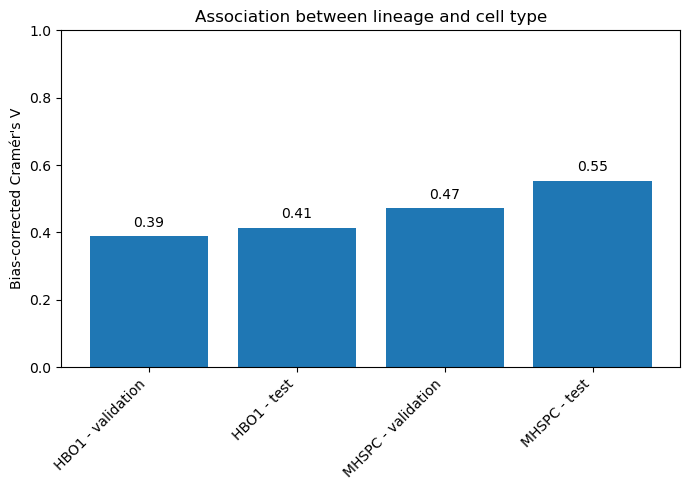

In [31]:
import matplotlib.pyplot as plt
import numpy as np

lot_df = (summary.loc[
        summary["split"].isin(["validation", "test"])
    ]
    .copy()
    .reset_index(drop=True)
)

labels = (
    plot_df["dataset_label"]
    + " - "
    + plot_df["split"]
)

values = plot_df["cramers_v_bias_corrected"].to_numpy()

x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(x, values)

ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    rotation=45,
    ha="right"
)

ax.set_ylabel("Bias-corrected Cramér's V")
ax.set_xlabel("")
ax.set_title("Association between lineage and cell type")

ax.set_ylim(
    0,
    max(1, values.max() * 1.15)
)

for i, value in enumerate(values):
    ax.text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

fig.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/validation_test_bias_corrected_cramers_v.pdf",
    bbox_inches="tight"
)

plt.show()

In [34]:
def plot_lineage_celltype_heatmap(
    table,
    dataset_label,
    split_name
):
    # Normalize within each lineage
    normalized = table.div(
        table.sum(axis=1),
        axis=0
    ).fillna(0)

    fig, ax = plt.subplots(
        figsize=(10, 7)
    )

    im = ax.imshow(
        normalized.values,
        aspect="auto",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(
        np.arange(
            len(normalized.columns)
        )
    )
    ax.set_xticklabels(
        normalized.columns.astype(str),
        rotation=90
    )

    ax.set_yticks(
        np.arange(
            len(normalized.index)
        )
    )
    ax.set_yticklabels(
        normalized.index.astype(str)
    )

    ax.set_xlabel("Cell type")
    ax.set_ylabel("Lineage")

    ax.set_title(
        f"{dataset_label} – {split_name}"
    )

    cbar = fig.colorbar(
        im,
        ax=ax
    )

    cbar.set_label(
        "Fraction of cells within lineage"
    )

    plt.tight_layout()


    fig.savefig(
        f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/{dataset_label}_{split_name}_lineage_celltype_heatmap.pdf",
        bbox_inches="tight"
    )

    plt.show()

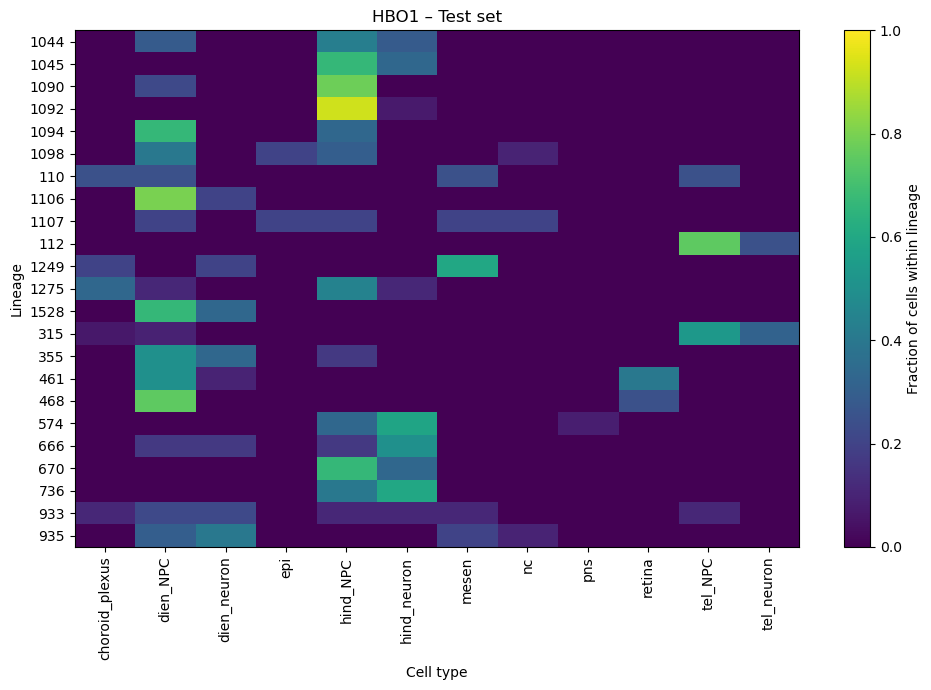

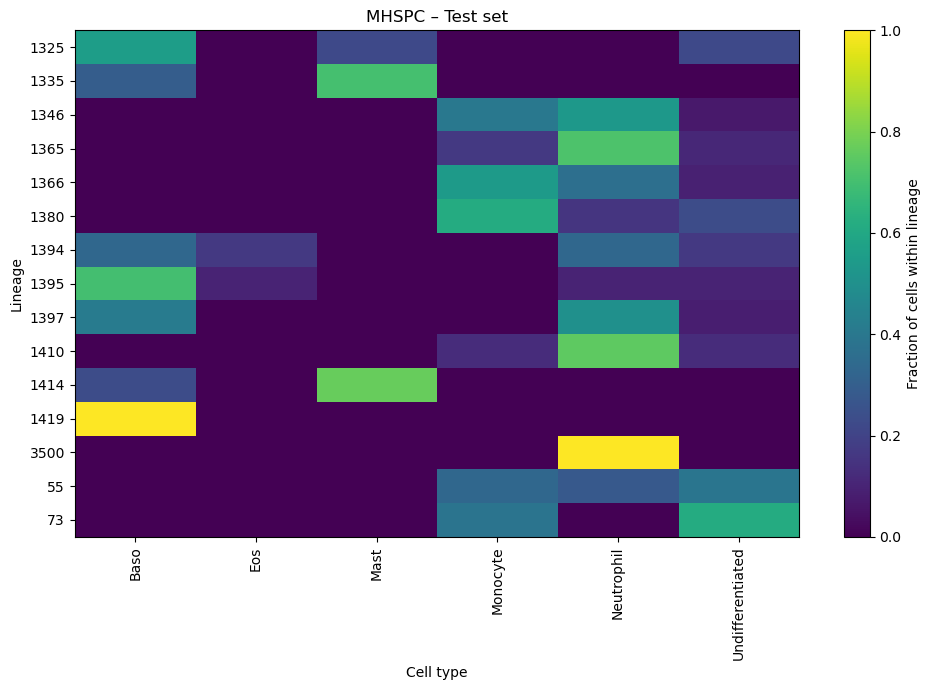

In [35]:
plot_lineage_celltype_heatmap(
    treutlein_tables["test"],
    "HBO1",
    "Test set"
)

plot_lineage_celltype_heatmap(
    weinreb_tables["test"],
    "MHSPC",
    "Test set"
)